# 03 — Classical Machine Learning Baselines

## Research focus

This notebook establishes the first measured baselines for TopicSense-NLP. It investigates how effectively established machine-learning methods can classify messages into the 20 categories of the 20 Newsgroups dataset.

Three classifiers are compared:

- **Multinomial Naive Bayes** — a probabilistic classifier that provides a fast and widely used baseline for text classification.
- **Logistic Regression** — a linear classification model that learns how individual features contribute to class predictions.
- **Linear Support Vector Machine (Linear SVM)** — a margin-based classifier that is often effective when text is represented by high-dimensional, sparse features.

Each classifier is evaluated with two feature representations:

- **Bag of Words (BoW):** represents documents using raw term counts.
- **TF-IDF:** weights terms according to their frequency in a document and their distribution across the training corpus.

Both feature representations are tested on two versions of each message: the complete message and its extracted body. This produces 12 configurations.

## How the comparison is conducted

All configurations use the same group-aware training and validation partitions established in Notebook 02. The training partition is used to fit the vectorizers and classifiers. The validation partition is used to compare the resulting models.

The official test partition remains untouched. It is reserved for the later evaluation stages and is not used to fit models, construct vocabularies or select configurations.

Macro-F1 is the primary comparison measure because it gives each of the 20 classes equal importance. Accuracy, macro precision, macro recall and weighted F1 provide additional perspectives on model performance.

The experiments also record fitting time, prediction time, prediction throughput and serialized pipeline size. These measurements help assess the practical cost of each approach alongside its predictive performance.

The implementation is maintained in reusable modules under `src/topicsense/`. Configuration is stored in `configs/classical_ml.yaml`, while this notebook brings the experiments and their findings together.

In [10]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )

SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

import topicsense.training.classical  # noqa: E402

run_classical_experiments = (
    topicsense.training.classical.run_classical_experiments
)

CONFIG_PATH = PROJECT_ROOT / "configs" / "classical_ml.yaml"

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

RANDOM_SEED = CONFIG["project"]["random_seed"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", context="notebook")

print(f"Project root: {PROJECT_ROOT}")
print(f"Random seed: {RANDOM_SEED}")
print(f"Configuration: {CONFIG_PATH}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Random seed: 42
Configuration: /home/nkululekocyrilcele/projects/topicsense-nlp/configs/classical_ml.yaml


## 1. Confirm the experiment inputs

Before training begins, the required dataset, development split and experiment configuration must be available.

The split manifest identifies the records assigned to training and validation in Notebook 02. The experiment runner uses those identifiers to construct the two partitions.

Although the raw dataset file contains both the official training and test records, the runner filters it to the official training partition before selecting the development records. The official test documents are therefore not passed to the vectorizers, classifiers or evaluation functions.

Keeping this separation is important. If information from the test partition influenced vocabulary construction, model fitting or configuration selection, the final evaluation would no longer provide an independent assessment.

In [11]:
RAW_DATA_PATH = PROJECT_ROOT / CONFIG["data"]["raw_dataset_path"]
SPLIT_PATH = PROJECT_ROOT / CONFIG["data"]["split_manifest_path"]

assert RAW_DATA_PATH.is_file(), RAW_DATA_PATH
assert SPLIT_PATH.is_file(), SPLIT_PATH
assert CONFIG_PATH.is_file(), CONFIG_PATH

print("Experiment inputs verified.")
print(f"Raw dataset: {RAW_DATA_PATH}")
print(f"Development split: {SPLIT_PATH}")

print("\nConfigured classifiers:")
for name, settings in CONFIG["classifiers"].items():
    print(f"- {name}: enabled={settings['enabled']}")

print("\nFeature representations:")
for feature_type in CONFIG["features"]["types"]:
    print(f"- {feature_type}")

print("\nText representations:")
for representation in CONFIG["preprocessing"]["representations"]:
    print(f"- {representation}")

Experiment inputs verified.
Raw dataset: /home/nkululekocyrilcele/projects/topicsense-nlp/data/raw/20newsgroups/20newsgroups_raw.jsonl
Development split: /home/nkululekocyrilcele/projects/topicsense-nlp/data/interim/20newsgroups/splits/official_training_split.json

Configured classifiers:
- multinomial_nb: enabled=True
- logistic_regression: enabled=True
- linear_svm: enabled=True

Feature representations:
- count
- tfidf

Text representations:
- full_message
- message_body


## 2. Train and evaluate the classical baselines

The experiment runner trains each enabled classifier using both feature representations and both text representations.

Each configuration is fitted independently. The vectorizer and classifier are combined in a scikit-learn pipeline, ensuring that vocabulary construction and feature weighting are learned from the training documents only.

The validation documents are then passed through the fitted pipeline to generate predictions. These predictions are used to calculate the classification metrics.

The experiment matrix contains 12 configurations:

- Three classifiers.
- Two feature representations.
- Two text representations.

All configurations use the same training and validation records, making their results directly comparable within this experiment.

The results below are validation measurements. They should not be described as final test performance.

In [12]:
EXPERIMENT_RESULTS = run_classical_experiments(
    CONFIG,
    project_root=PROJECT_ROOT,
)

results_df = pd.DataFrame(EXPERIMENT_RESULTS["summary"])

print(f"Completed configurations: {len(results_df)}")

display(
    results_df.sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    ).reset_index(drop=True)
)

multinomial_nb__count__full_message: macro-F1=0.8272, accuracy=0.8383, fit=12.21s
logistic_regression__count__full_message: macro-F1=0.8731, accuracy=0.8732, fit=109.50s
linear_svm__count__full_message: macro-F1=0.8789, accuracy=0.8780, fit=42.71s
multinomial_nb__tfidf__full_message: macro-F1=0.8293, accuracy=0.8409, fit=10.65s
logistic_regression__tfidf__full_message: macro-F1=0.8795, accuracy=0.8811, fit=42.96s
linear_svm__tfidf__full_message: macro-F1=0.9138, accuracy=0.9147, fit=16.27s
multinomial_nb__count__message_body: macro-F1=0.8046, accuracy=0.8193, fit=9.46s
logistic_regression__count__message_body: macro-F1=0.8219, accuracy=0.8219, fit=149.12s
linear_svm__count__message_body: macro-F1=0.8046, accuracy=0.8060, fit=93.49s
multinomial_nb__tfidf__message_body: macro-F1=0.8053, accuracy=0.8184, fit=12.77s
logistic_regression__tfidf__message_body: macro-F1=0.8550, accuracy=0.8604, fit=60.86s
linear_svm__tfidf__message_body: macro-F1=0.8947, accuracy=0.8966, fit=23.66s
Completed c

,run_id,experiment_id,classifier,feature_type,representation,training_documents,validation_documents,feature_count,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,latency_ms_per_document,throughput_documents_per_second,artifact_size_bytes
0,linear_svm__tfidf__full_message,EXP-03,linear_svm,tfidf,full_message,9051,2263,100000,0.914715,0.916963,0.912511,0.913779,0.914656,16.272518,1.497256,0.661624,1511.431421,19902488
1,linear_svm__tfidf__message_body,EXP-03,linear_svm,tfidf,message_body,9051,2263,100000,0.896597,0.899874,0.892915,0.894659,0.896266,23.657301,1.587699,0.701591,1425.332714,19900296
2,logistic_regression__tfidf__full_message,EXP-02,logistic_regression,tfidf,full_message,9051,2263,100000,0.881131,0.888241,0.876884,0.879464,0.881175,42.960534,1.257566,0.555708,1799.507422,19902636
3,linear_svm__count__full_message,EXP-03,linear_svm,count,full_message,9051,2263,100000,0.878038,0.882270,0.876982,0.878894,0.878494,42.706394,1.436764,0.634893,1575.067329,19102389
4,logistic_regression__count__full_message,EXP-02,logistic_regression,count,full_message,9051,2263,100000,0.873177,0.877364,0.871022,0.873074,0.873539,109.500007,1.941113,0.857761,1165.825842,19102536
5,logistic_regression__tfidf__message_body,EXP-02,logistic_regression,tfidf,message_body,9051,2263,100000,0.860362,0.872132,0.852760,0.854986,0.859162,60.855575,1.445385,0.638703,1565.672686,19900444
6,multinomial_nb__tfidf__full_message,EXP-01,multinomial_nb,tfidf,full_message,9051,2263,100000,0.840919,0.865745,0.828533,0.829320,0.837485,10.651674,1.819133,0.803859,1243.999207,35902689
7,multinomial_nb__count__full_message,EXP-01,multinomial_nb,count,full_message,9051,2263,100000,0.838268,0.855845,0.837584,0.827190,0.826129,12.207935,0.904348,0.399624,2502.354557,35102605
8,logistic_regression__count__message_body,EXP-02,logistic_regression,count,message_body,9051,2263,100000,0.821918,0.829420,0.818797,0.821850,0.822896,149.121680,1.796869,0.794021,1259.412841,19100344
9,multinomial_nb__tfidf__message_body,EXP-01,multinomial_nb,tfidf,message_body,9051,2263,100000,0.818383,0.854553,0.803533,0.805293,0.815361,12.769708,1.624283,0.717757,1393.230022,35900497


### Initial observations

The recorded execution completed all 12 configurations using 9,051 training documents and 2,263 validation documents.

The strongest observed result came from Linear SVM with TF-IDF features and complete messages. It achieved a validation macro-F1 of **0.9138** and an accuracy of **0.9147**.

The corresponding Linear SVM configuration using message bodies achieved a macro-F1 of **0.8947**. This suggests that the complete-message representation contains additional signals that are useful for distinguishing the newsgroup categories.

That difference needs careful interpretation. Complete messages can contain headers, quoted replies and other contextual material in addition to the author's main message. Some of these signals may be specific to the structure of this benchmark rather than representing general topic information.

There is also an important qualification: both count-based Linear SVM configurations emitted convergence warnings in the recorded execution. Their results are included for completeness, but should be treated as provisional until those configurations are rerun with a higher iteration limit and convergence is confirmed.

The next sections examine the results in more detail rather than relying on the overall ranking alone.

## 3. Compare aggregate classification performance

Macro-F1 is the primary measure used to rank the configurations. It calculates the F1-score for each class and then averages those scores, giving every class equal weight.

This is useful for a multi-class dataset because a model should not appear successful solely because it performs well on the classes with the greatest representation.

The other measures provide complementary information:

- **Accuracy** is the proportion of all validation documents classified correctly.
- **Macro precision** measures the average precision across the classes.
- **Macro recall** measures the average recall across the classes.
- **Weighted F1** averages class F1-scores while accounting for the number of documents in each class.

The table is sorted by validation macro-F1, with accuracy used as a secondary ordering measure. It identifies promising configurations for subsequent experiments, not a final project winner.

In [13]:
performance_columns = [
    "classifier",
    "feature_type",
    "representation",
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
]

performance_table = (
    results_df[performance_columns]
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    performance_table.style.format(
        {
            "accuracy": "{:.4f}",
            "macro_precision": "{:.4f}",
            "macro_recall": "{:.4f}",
            "macro_f1": "{:.4f}",
            "weighted_f1": "{:.4f}",
        }
    )
)

best_run_summary = performance_table.iloc[0]

print("Best validation configuration by macro-F1:")
display(best_run_summary.to_frame(name="value"))

,classifier,feature_type,representation,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,linear_svm,tfidf,full_message,0.9147,0.9170,0.9125,0.9138,0.9147
1,linear_svm,tfidf,message_body,0.8966,0.8999,0.8929,0.8947,0.8963
2,logistic_regression,tfidf,full_message,0.8811,0.8882,0.8769,0.8795,0.8812
3,linear_svm,count,full_message,0.8780,0.8823,0.8770,0.8789,0.8785
4,logistic_regression,count,full_message,0.8732,0.8774,0.8710,0.8731,0.8735
5,logistic_regression,tfidf,message_body,0.8604,0.8721,0.8528,0.8550,0.8592
6,multinomial_nb,tfidf,full_message,0.8409,0.8657,0.8285,0.8293,0.8375
7,multinomial_nb,count,full_message,0.8383,0.8558,0.8376,0.8272,0.8261
8,logistic_regression,count,message_body,0.8219,0.8294,0.8188,0.8219,0.8229
9,multinomial_nb,tfidf,message_body,0.8184,0.8546,0.8035,0.8053,0.8154


Best validation configuration by macro-F1:


,value
classifier,linear_svm
feature_type,tfidf
representation,full_message
accuracy,0.914715
macro_precision,0.916963
macro_recall,0.912511
macro_f1,0.913779
weighted_f1,0.914656


### Interpreting the aggregate results

The recorded results show a clear advantage for Linear SVM with TF-IDF features. Its complete-message configuration achieved the highest macro-F1 (**0.9138**), followed by the message-body configuration (**0.8947**).

Logistic Regression with TF-IDF and complete messages achieved a macro-F1 of **0.8795**, while Multinomial Naive Bayes with TF-IDF and complete messages achieved **0.8293**.

The comparison also suggests that TF-IDF is particularly beneficial for the Linear SVM configurations. With complete messages, its macro-F1 increased from **0.8793** using raw counts to **0.9138** using TF-IDF. With message bodies, it increased from **0.8046** to **0.8947**.

The difference between complete messages and message bodies is also consistent across the recorded configurations: complete-message representations achieved higher macro-F1 scores in all six matched comparisons.

These results suggest that both feature weighting and the choice of text representation influence classification performance. However, the apparent advantage of complete messages needs further investigation because the full text may contain metadata and quoted material that provide dataset-specific clues.

The results are based on one fixed validation partition. They do not establish statistical significance, and small differences between configurations should not automatically be interpreted as meaningful improvements.

## 4. Examine performance across individual classes

Aggregate metrics are useful for comparing models, but they can conceal substantial differences between categories.

The following table examines precision, recall and F1-score for each of the 20 classes using the configuration with the highest validation macro-F1.

Class-level results are particularly useful in this project because the newsgroup categories cover a mixture of technical, recreational, political and religious discussions. Some categories may have more distinctive vocabulary than others, while related discussions may share terminology.

The support column shows how many validation documents belong to each class. It provides context for interpreting the individual scores.

In [14]:
best_run_id = str(best_run_summary["classifier"]) + "__" + str(
    best_run_summary["feature_type"]
) + "__" + str(best_run_summary["representation"])

best_run = next(
    run
    for run in EXPERIMENT_RESULTS["runs"]
    if run["run_id"] == best_run_id
)

best_per_class = pd.DataFrame.from_dict(
    best_run["metrics"]["per_class"],
    orient="index",
)

best_per_class.index.name = "class"

display(
    best_per_class.sort_values(
        "f1_score",
        ascending=True,
    ).style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
        }
    )
)

,precision,recall,f1_score,support
class,,,,
comp.sys.ibm.pc.hardware,0.7863,0.7797,0.7830,118
comp.graphics,0.7846,0.8793,0.8293,116
talk.religion.misc,0.9344,0.7500,0.8321,76
misc.forsale,0.8443,0.8803,0.8619,117
comp.windows.x,0.8678,0.8824,0.8750,119
comp.os.ms-windows.misc,0.8618,0.8983,0.8797,118
sci.electronics,0.9259,0.8403,0.8811,119
comp.sys.mac.hardware,0.8879,0.8957,0.8918,115
rec.autos,0.9474,0.9076,0.9270,119


### Interpreting the class-level results

The class-level results show that the strongest overall configuration does not perform equally well across all categories.

The lowest F1-score is observed for `comp.sys.ibm.pc.hardware` (**0.7830**). Its precision and recall are both relatively low, suggesting that the model has difficulty distinguishing some documents in this category from other topics.

`comp.graphics` achieves an F1-score of **0.8293**. Its recall (**0.8793**) is higher than its precision (**0.7846**), indicating that the model identifies a relatively large proportion of the actual examples but also assigns some documents from other categories to this class.

`talk.religion.misc` achieves an F1-score of **0.8321**. Its precision is high (**0.9344**), but recall is lower (**0.7500**). In practical terms, predictions assigned to this class are often correct, but the model misses a notable share of documents that actually belong to it.

At the stronger end, `talk.politics.mideast` reaches an F1-score of **0.9826**, while `sci.space` reaches **0.9787**.

These differences show why macro-F1 and per-class reporting are important. A strong overall result does not mean that every topic is classified equally well.

The scores identify where further investigation may be useful, but they do not explain the underlying causes of the errors. The confusion analysis provides another view of those mistakes.

## 5. Inspect the confusion matrix

The confusion matrix provides a more detailed view of the predictions made by the strongest validation configuration.

Rows represent the actual classes, while columns represent the predicted classes. Values along the diagonal represent correct classifications. Values outside the diagonal represent documents assigned to an incorrect category.

The matrix contains 20 rows and 20 columns, one for each newsgroup category.

Because the full matrix can be difficult to inspect visually, the following analysis also ranks the most frequent incorrect class assignments. This makes it easier to identify which pairs of categories account for the largest numbers of errors.

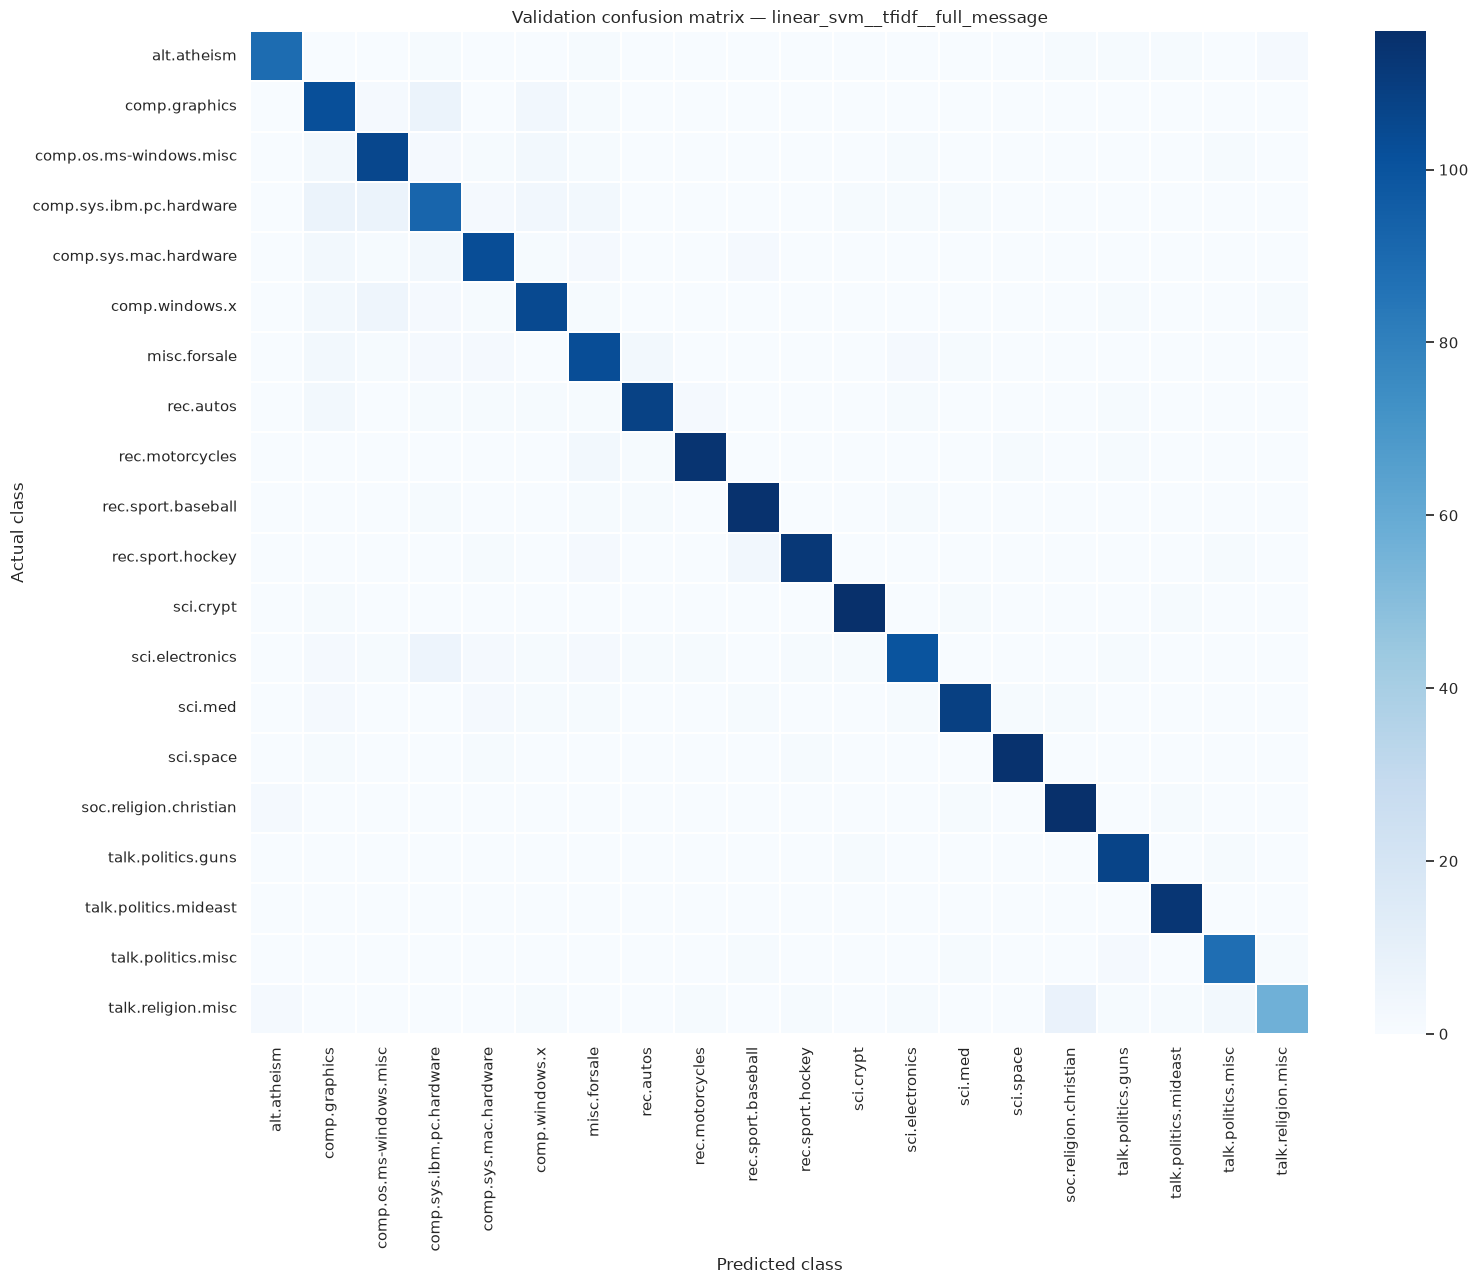

In [15]:
class_labels = best_run["metrics"]["class_labels"]

confusion_df = pd.DataFrame(
    best_run["metrics"]["confusion_matrix"],
    index=class_labels,
    columns=class_labels,
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    confusion_df,
    cmap="Blues",
    annot=False,
    fmt="d",
    linewidths=0.1,
)

plt.title(f"Validation confusion matrix — {best_run_id}")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:

# Create a writable copy of the confusion matrix.
confusion_values = confusion_df.to_numpy(copy=True)

# Remove correct predictions from the matrix so that only
# incorrect actual-versus-predicted class assignments remain.
np.fill_diagonal(confusion_values, 0)

off_diagonal = pd.DataFrame(
    confusion_values,
    index=confusion_df.index,
    columns=confusion_df.columns,
)

# Rank the ten most frequent incorrect class assignments.
largest_confusions = (
    off_diagonal.rename_axis("actual_class")
    .reset_index()
    .melt(
        id_vars="actual_class",
        var_name="predicted_class",
        value_name="document_count",
    )
    .query("document_count > 0")
    .sort_values(
        "document_count",
        ascending=False,
    )
    .head(10)
    .reset_index(drop=True)
)

display(largest_confusions)

,actual_class,predicted_class,document_count
0,talk.religion.misc,soc.religion.christian,8
1,comp.sys.ibm.pc.hardware,comp.graphics,7
2,comp.graphics,comp.sys.ibm.pc.hardware,7
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,7
4,sci.electronics,comp.sys.ibm.pc.hardware,6
5,comp.windows.x,comp.os.ms-windows.misc,5
6,comp.sys.ibm.pc.hardware,comp.windows.x,4
7,comp.graphics,comp.windows.x,4
8,rec.sport.hockey,rec.sport.baseball,4
9,comp.os.ms-windows.misc,comp.graphics,3


### Interpreting the confusion analysis

The ranked error pairs show that some of the model's mistakes occur between categories covering related or potentially overlapping subject matter.

The most frequent confusion involves `talk.religion.misc` being classified as `soc.religion.christian`, with eight validation documents assigned this way. Several other prominent errors occur among computer-related categories. For example, seven `comp.sys.ibm.pc.hardware` documents are classified as `comp.graphics`, while another seven `comp.graphics` documents are classified as `comp.sys.ibm.pc.hardware`.

The results also show confusion between `comp.sys.ibm.pc.hardware` and `comp.os.ms-windows.misc`, as well as between `rec.sport.hockey` and `rec.sport.baseball`.

These observations identify category pairs that deserve closer examination. Shared terminology, related subject matter and messages discussing multiple topics are possible explanations, but the confusion counts alone cannot establish why individual documents were misclassified.

The later error-analysis stage will examine individual examples to investigate these mistakes in greater detail. For now, the confusion analysis provides a reproducible summary of the model's errors and identifies useful areas for further investigation.

## 6. Compare feature and text representations

The experiment matrix allows us to examine how the choice of feature representation and source text affects the three classifiers.

The grouped chart compares validation macro-F1 across the 12 configurations. It separates complete messages from message bodies and distinguishes raw term counts from TF-IDF.

This makes it easier to see whether a particular feature representation consistently helps a classifier, and whether the relative ranking changes when the source text is restricted to the message body.

The chart is descriptive and reflects this particular dataset and validation split. It should not be interpreted as evidence that one representation will always be superior in other classification tasks.

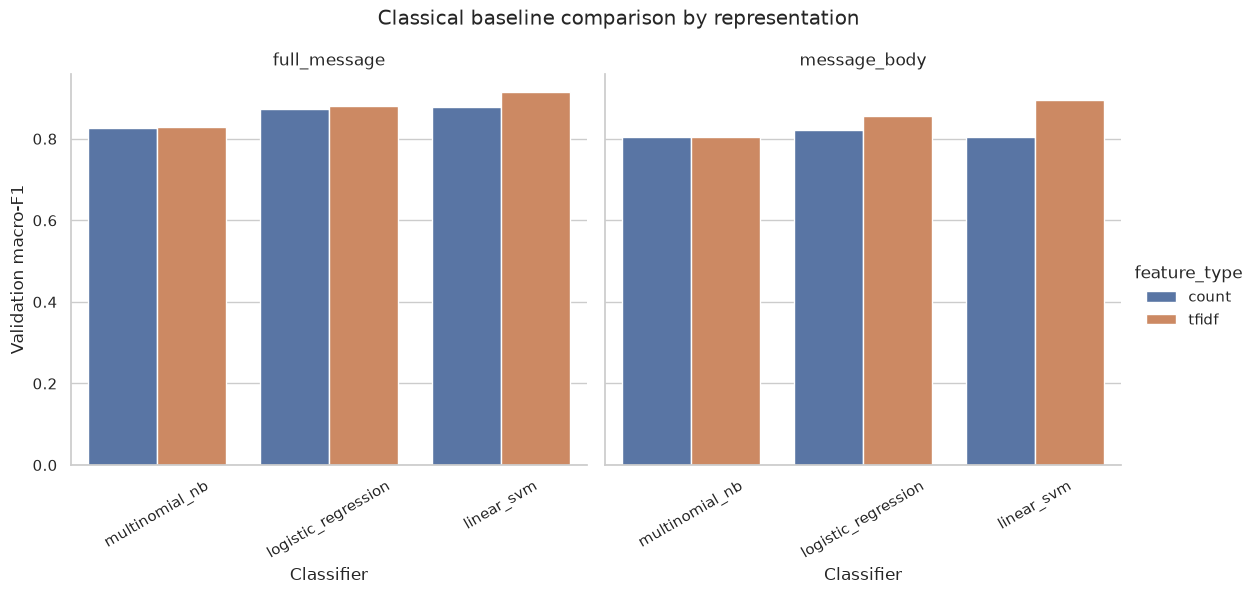

Saved comparison figure: /home/nkululekocyrilcele/projects/topicsense-nlp/results/figures/classical_baseline_comparison.png


In [17]:
comparison_plot = sns.catplot(
    data=results_df,
    x="classifier",
    y="macro_f1",
    hue="feature_type",
    col="representation",
    kind="bar",
    height=5,
    aspect=1.15,
    sharey=True,
)

comparison_plot.set_axis_labels(
    "Classifier",
    "Validation macro-F1",
)

comparison_plot.set_titles("{col_name}")

comparison_plot.set_xticklabels(rotation=30)

comparison_plot.figure.suptitle(
    "Classical baseline comparison by representation",
    y=1.05,
)

plt.show()

figure_path = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / "classical_baseline_comparison.png"
)

figure_path.parent.mkdir(parents=True, exist_ok=True)

comparison_plot.figure.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved comparison figure: {figure_path}")

### Interpreting the representation comparison

The recorded results show that TF-IDF improves the Linear SVM results over raw term counts for both text representations.

For complete messages, Linear SVM macro-F1 increases from **0.8793** with raw counts to **0.9138** with TF-IDF. For message bodies, it increases from **0.8046** to **0.8947**.

The effect is less pronounced for Multinomial Naive Bayes. Its complete-message macro-F1 changes from **0.8272** with raw counts to **0.8293** with TF-IDF. This suggests that the benefit of TF-IDF depends partly on the classifier being used.

The chart also shows that complete messages outperform message bodies across the tested classifier and feature combinations in this execution.

This is an important finding, but it should not be interpreted as proof that message headers and quoted material improve genuine topic understanding. Those elements may contain recurring dataset-specific signals. The later preprocessing experiments will help determine how much of the observed advantage remains when text handling is controlled more carefully.

The results therefore support retaining both text representations for subsequent experiments rather than making an irreversible decision based on this baseline comparison alone.

## 7. Consider computational efficiency

Classification quality is only one part of the comparison. A model may achieve strong predictive performance but require substantially more time or storage than another approach.

The experiment runner records:

- **Fitting time:** the time required to fit the vectorizer and classifier.
- **Prediction time:** the time required to generate predictions for the complete validation batch.
- **Average latency per document:** prediction time divided by the number of validation documents.
- **Throughput:** the number of validation documents processed per second.
- **Serialized artifact size:** the size of the fitted vectorizer and classifier when saved together.

These measurements were collected in the same execution environment, making them useful for an initial comparison. They are nevertheless specific to this machine, software environment, dataset and batch size.

The latency and throughput figures are batch-derived measurements. They should not be interpreted as measurements of single-request latency in a deployed API.

In [18]:
efficiency_columns = [
    "classifier",
    "feature_type",
    "representation",
    "fit_seconds",
    "prediction_seconds",
    "latency_ms_per_document",
    "throughput_documents_per_second",
    "artifact_size_bytes",
]

efficiency_table = results_df[efficiency_columns].sort_values(
    ["fit_seconds", "prediction_seconds"],
    ascending=True,
)

display(
    efficiency_table.style.format(
        {
            "fit_seconds": "{:.3f}",
            "prediction_seconds": "{:.4f}",
            "latency_ms_per_document": "{:.4f}",
            "throughput_documents_per_second": "{:.2f}",
            "artifact_size_bytes": "{:,.0f}",
        }
    )
)

,classifier,feature_type,representation,fit_seconds,prediction_seconds,latency_ms_per_document,throughput_documents_per_second,artifact_size_bytes
6,multinomial_nb,count,message_body,9.465,1.1184,0.4942,2023.41,"35,100,413"
3,multinomial_nb,tfidf,full_message,10.652,1.8191,0.8039,1244.00,"35,902,689"
0,multinomial_nb,count,full_message,12.208,0.9043,0.3996,2502.35,"35,102,605"
9,multinomial_nb,tfidf,message_body,12.770,1.6243,0.7178,1393.23,"35,900,497"
5,linear_svm,tfidf,full_message,16.273,1.4973,0.6616,1511.43,"19,902,488"
11,linear_svm,tfidf,message_body,23.657,1.5877,0.7016,1425.33,"19,900,296"
2,linear_svm,count,full_message,42.706,1.4368,0.6349,1575.07,"19,102,389"
4,logistic_regression,tfidf,full_message,42.961,1.2576,0.5557,1799.51,"19,902,636"
10,logistic_regression,tfidf,message_body,60.856,1.4454,0.6387,1565.67,"19,900,444"
8,linear_svm,count,message_body,93.491,1.3559,0.5992,1669.00,"19,100,197"


### Interpreting the efficiency measurements

The recorded fitting times show that Multinomial Naive Bayes is generally the quickest classifier to train in this experiment. Its configurations complete fitting in approximately 9–16 seconds.

Logistic Regression takes longer, with the count-based message-body configuration requiring approximately 192 seconds in the recorded run. The count-based Linear SVM configurations also require substantially more fitting time than their TF-IDF counterparts.

The TF-IDF Linear SVM configurations combine the strongest observed validation scores with fitting times of approximately 13–17 seconds. This makes them promising candidates for further evaluation, although their performance must still be confirmed through the later test and sensitivity analyses.

Prediction time is considerably shorter than fitting time across the configurations. The reported per-document latency and throughput are calculated from the complete validation batch. They do not measure the overhead of handling individual requests through the future FastAPI application.

The serialized artifact sizes also differ. In this run, the Naive Bayes pipelines are approximately 35–36 MB, while the Logistic Regression and Linear SVM pipelines are approximately 19–20 MB. These measurements include the fitted vectorizer and vocabulary, not just the classifier parameters.

All timing and storage measurements should be treated as observations from this execution environment. They provide a useful baseline for later comparisons, but should not be generalized to other hardware without further measurement.

## 8. Confirm the experiment outputs

The experiment runner stores the aggregate metrics in CSV format and the detailed run information in JSON format. The comparison figure is also saved for use in subsequent analysis and reporting.

The detailed JSON contains the individual run records, model parameters, class-level metrics and confusion matrices. The CSV provides a more compact view that can be used to compare configurations across later experiments.

These outputs form the hand-off to the model-comparison and error-analysis stages.

Model registration and experiment tracking through MLflow are not introduced here. Those capabilities will be implemented as part of the dedicated experiment-management work.

In [19]:
output_paths = {
    "metrics_csv": PROJECT_ROOT / EXPERIMENT_RESULTS["metrics_csv"],
    "results_json": PROJECT_ROOT / EXPERIMENT_RESULTS["results_json"],
    "comparison_figure": figure_path,
}

print("Experiment output files")

for name, path in output_paths.items():
    print(f"{name}: {path} — {'FOUND' if path.is_file() else 'MISSING'}")

assert len(results_df) == 12
assert results_df["macro_f1"].between(0.0, 1.0).all()
assert results_df["accuracy"].between(0.0, 1.0).all()
assert results_df["training_documents"].eq(9051).all()
assert results_df["validation_documents"].eq(2263).all()
assert results_df["feature_count"].gt(0).all()
assert all(path.is_file() for path in output_paths.values())

assert len(best_run["metrics"]["class_labels"]) == 20
assert len(best_run["metrics"]["per_class"]) == 20
assert confusion_df.shape == (20, 20)

print("\nBaseline output checks passed.")

Experiment output files
metrics_csv: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/classical_baselines.csv — FOUND
results_json: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/classical_baselines.json — FOUND
comparison_figure: /home/nkululekocyrilcele/projects/topicsense-nlp/results/figures/classical_baseline_comparison.png — FOUND

Baseline output checks passed.


## 9. Findings, limitations and next steps

These experiments establish the first measured classical machine-learning baselines for TopicSense-NLP.

Among the 12 recorded configurations, Linear SVM with TF-IDF and complete messages achieved the highest validation macro-F1 (**0.9138**) and accuracy (**0.9147**). Its message-body counterpart achieved a macro-F1 of **0.8947**.

The results also indicate that TF-IDF is particularly effective for Linear SVM in this experiment. The complete-message representation achieved higher validation macro-F1 than the message-body representation across all six matched comparisons.

The class-level results show that performance varies across categories. The model performs particularly well on some topics, such as `talk.politics.mideast` and `sci.space`, while categories such as `comp.sys.ibm.pc.hardware`, `comp.graphics` and `talk.religion.misc` remain more difficult.

The confusion matrix provides a structured view of the model's errors and identifies category pairs for more detailed investigation. The computational measurements add another dimension to the comparison by showing the time and storage requirements associated with each approach.

### Limitations

Several qualifications are important when interpreting these findings:

1. The results come from one fixed validation partition of the 20 Newsgroups training data.
2. The official test partition has not been used and must remain reserved for final evaluation.
3. The count-based Linear SVM configurations emitted convergence warnings in the recorded execution. Their scores must be confirmed through a warning-free rerun before they are treated as settled.
4. The advantage of complete messages may partly reflect dataset-specific metadata, quoted material or recurring message conventions.
5. Runtime and artifact-size measurements are specific to the current hardware and software environment.
6. The results do not establish cross-domain generalisation or statistical significance.

### Next steps

The classical baselines provide a reference point for the next experiments. The planned work will investigate training-size effects, controlled preprocessing choices, hyperparameter optimisation and the performance of neural and transformer-based models.

The clean-test and decontaminated-training sensitivity tracks established in Notebook 02 must also be retained. Their results should be reported separately from the official benchmark rather than combined into a single score.

The strongest validation configuration is therefore a promising candidate for further investigation, not a final project winner. Final conclusions will be based on the complete set of measured experiments, including the reserved test evaluation and the documented limitations.